<a href="https://colab.research.google.com/github/mithulkannan17/Machine_learning_2/blob/main/First_Order_Inductive_Learner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Read a dataset and use an example-based method (RIPPER/CN2) to generate classification rules. Apply the FOIL algorithm (First-Order Inductive Learner) to learn first-order rules for prediction



Dataset:
  Weather    Wind Play
0   Sunny    Weak  Yes
1   Sunny  Strong   No
2   Rainy    Weak  Yes
3   Rainy  Strong   No
4  Cloudy    Weak  Yes
5  Cloudy  Strong  Yes

Information Gain:
Weather: 0.252
Wind: 0.459

Classification Rules:
IF Weather = Sunny AND Wind = Weak THEN Play = Yes
IF Weather = Sunny AND Wind = Strong THEN Play = No
IF Weather = Rainy AND Wind = Weak THEN Play = Yes
IF Weather = Rainy AND Wind = Strong THEN Play = No
IF Weather = Cloudy AND Wind = Weak THEN Play = Yes
IF Weather = Cloudy AND Wind = Strong THEN Play = Yes

FOIL Rules:
IF Weather = Cloudy THEN Play = Yes

FOIL Positive and Negative Examples:
Positive: 4
Negative: 2


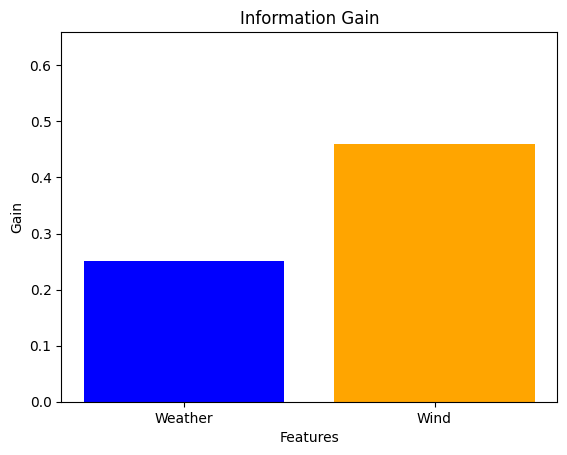

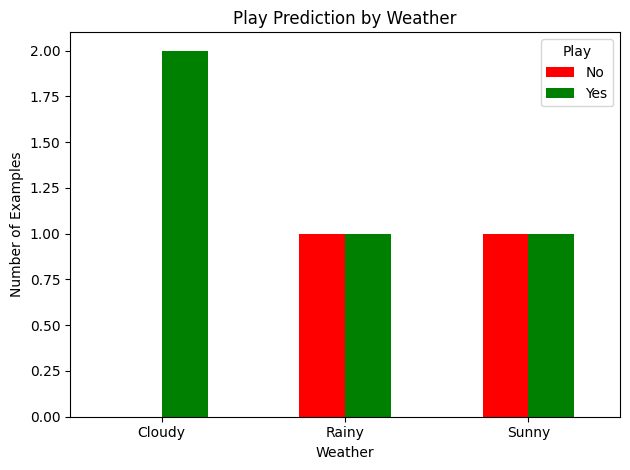

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import math

data = pd.DataFrame({
    "Weather": ["Sunny", "Sunny", "Rainy", "Rainy", "Cloudy", "Cloudy"],
    "Wind": ["Weak", "Strong", "Weak", "Strong", "Weak", "Strong"],
    "Play": ["Yes", "No", "Yes", "No", "Yes", "Yes"]
})

print("Dataset:")
print(data)

def entropy(values):
    counts = values.value_counts()
    total = len(values)
    return -sum((c / total) * math.log2(c / total) for c in counts)

def information_gain(data, feature, target):
    total_entropy = entropy(data[target])
    weighted_entropy = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]
        weighted_entropy += (len(subset) / len(data)) * entropy(subset[target])

    return total_entropy - weighted_entropy

print("\nInformation Gain:")

for feature in ["Weather", "Wind"]:
    gain = information_gain(data, feature, "Play")
    print(f"{feature}: {gain:.3f}")

print("\nClassification Rules:")

for weather in data["Weather"].unique():
    for wind in data["Wind"].unique():
        rows = data[(data["Weather"] == weather) & (data["Wind"] == wind)]

        if len(rows) > 0:
            result = rows["Play"].mode()[0]
            print(f"IF Weather = {weather} AND Wind = {wind} THEN Play = {result}")

print("\nFOIL Rules:")

positive = data[data["Play"] == "Yes"]

for weather in positive["Weather"].unique():
    rows = positive[positive["Weather"] == weather]
    negative = data[(data["Weather"] == weather) & (data["Play"] == "No")]

    if len(negative) == 0:
        print(f"IF Weather = {weather} THEN Play = Yes")

print("\nFOIL Positive and Negative Examples:")
print("Positive:", len(positive))
print("Negative:", len(data[data["Play"] == "No"]))

gain_values = {
    "Weather": information_gain(data, "Weather", "Play"),
    "Wind": information_gain(data, "Wind", "Play")
}

plt.bar(gain_values.keys(), gain_values.values(), color=["blue", "orange"])
plt.title("Information Gain")
plt.xlabel("Features")
plt.ylabel("Gain")
plt.ylim(0, max(gain_values.values()) + 0.2)
plt.show()

plot = pd.crosstab(data["Weather"], data["Play"])
plot.plot(kind="bar", color=["red", "green"])
plt.title("Play Prediction by Weather")
plt.xlabel("Weather")
plt.ylabel("Number of Examples")
plt.xticks(rotation=0)
plt.legend(title="Play")
plt.tight_layout()
plt.show()


Dataset:
     Weather Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No

Information Gain:
Weather: 0.247
Temperature: 0.029
Humidity: 0.152
Wind: 0.048

Classification Rules:
IF Weather = Sunny AND Wind = Weak THEN Play = No
IF Weather = Sunny AND Wind = Strong THEN Play = No
IF Weather = Overcast AND Wind = Weak THEN Play = Yes
IF Weather = Overcast AND 

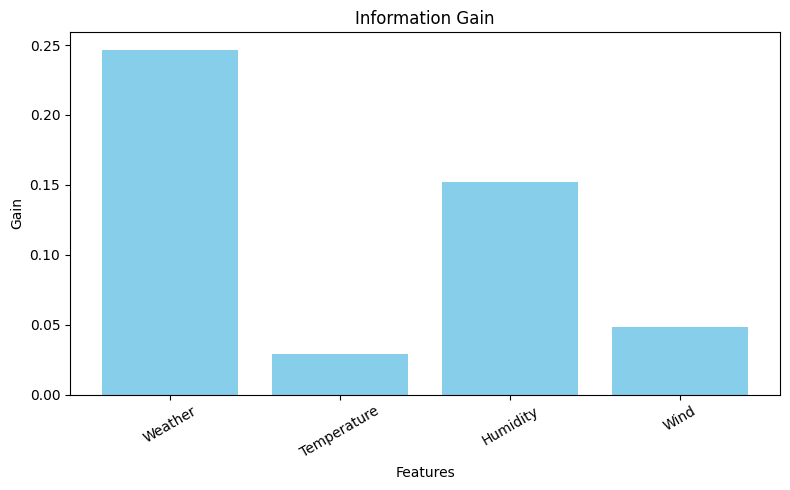

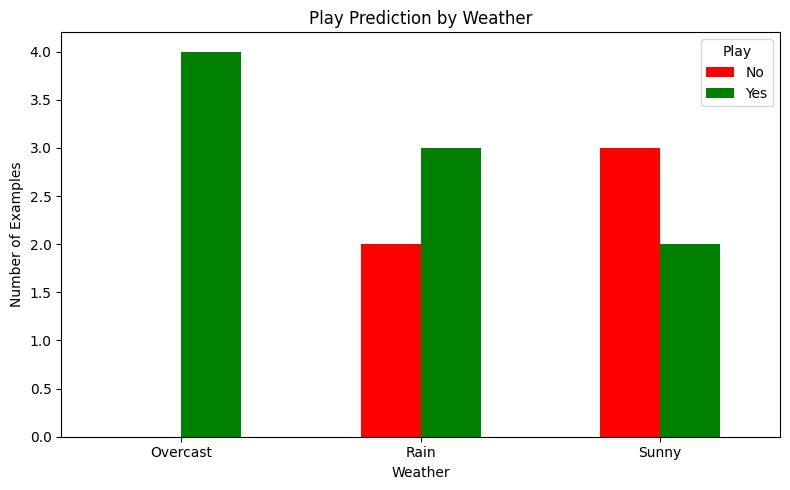

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import math

url = "https://gist.githubusercontent.com/DiogoRibeiro7/c6590d0cf119e87c39e31c21a9c0f3a8/raw/PlayTennis.csv"

data = pd.read_csv(url)

data.columns = ["Weather", "Temperature", "Humidity", "Wind", "Play"]


print("Dataset:")
print(data)

def entropy(values):
    counts = values.value_counts()
    total = len(values)
    return -sum((c / total) * math.log2(c / total) for c in counts)

def information_gain(data, feature, target):
    total_entropy = entropy(data[target])
    weighted_entropy = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]
        weighted_entropy += (len(subset) / len(data)) * entropy(subset[target])

    return total_entropy - weighted_entropy

print("\nInformation Gain:")

features = ["Weather", "Temperature", "Humidity", "Wind"]

gain_values = {}

for feature in features:
    gain = information_gain(data, feature, "Play")
    gain_values[feature] = gain
    print(f"{feature}: {gain:.3f}")

print("\nClassification Rules:")

for weather in data["Weather"].unique():
    for wind in data["Wind"].unique():
        rows = data[(data["Weather"] == weather) & (data["Wind"] == wind)]

        if len(rows) > 0:
            result = rows["Play"].mode()[0]
            print(f"IF Weather = {weather} AND Wind = {wind} THEN Play = {result}")

print("\nFOIL Rules:")

positive = data[data["Play"] == "Yes"]

for weather in positive["Weather"].unique():
    negative = data[
        (data["Weather"] == weather) &
        (data["Play"] == "No")
    ]

    if len(negative) == 0:
        print(f"IF Weather = {weather} THEN Play = Yes")

print("\nFOIL Positive and Negative Examples:")
print("Positive:", len(data[data["Play"] == "Yes"]))
print("Negative:", len(data[data["Play"] == "No"]))

plt.figure(figsize=(8, 5))
plt.bar(gain_values.keys(), gain_values.values(), color="skyblue")
plt.title("Information Gain")
plt.xlabel("Features")
plt.ylabel("Gain")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plot = pd.crosstab(data["Weather"], data["Play"])

plot.plot(
    kind="bar",
    color=["red", "green"],
    figsize=(8, 5)
)

plt.title("Play Prediction by Weather")
plt.xlabel("Weather")
plt.ylabel("Number of Examples")
plt.xticks(rotation=0)
plt.legend(title="Play")
plt.tight_layout()
plt.show()
